# 03 – Segmentace

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import cv2
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from coins.io import load_rgb, show_images, SAMPLE_DIR
from coins.preprocess import preprocess
from coins.segment import threshold_hysteresis, clean_mask, segment, find_coins, draw_coins

In [2]:
images = {name: load_rgb(SAMPLE_DIR / name) for name in ["1.jpg", "2.jpg"]}
v = {name: preprocess(img) for name, img in images.items()}

## Srovnání metod prahování

In [3]:
def thresholds(v):
    return {
        "Otsu": cv2.threshold(v, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1],
        "Triangle": cv2.threshold(v, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_TRIANGLE)[1],
        "adaptivní": cv2.adaptiveThreshold(v, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 201, -10),
        "hystereze": threshold_hysteresis(v),
    }

rows = []
for name, img in v.items():
    for method, mask in thresholds(img).items():
        rows.append({"snímek": name, "metoda": method, "mincí": len(find_coins(clean_mask(mask)))})
pd.DataFrame(rows).pivot(index="metoda", columns="snímek", values="mincí")

snímek,1.jpg,2.jpg
metoda,,
Otsu,10,2
Triangle,10,2
adaptivní,11,2
hystereze,11,2


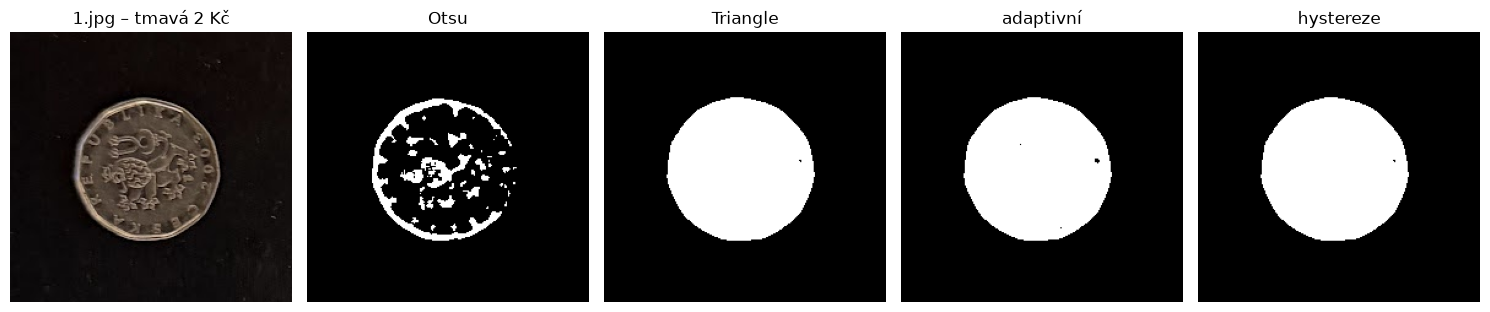

In [4]:
t1 = thresholds(v["1.jpg"])
crop = (slice(480, 700), slice(40, 270))
show_images([images["1.jpg"][crop]] + [m[crop] for m in t1.values()],
            ["1.jpg – tmavá 2 Kč"] + list(t1.keys()), cols=5, size=3)

## Morfologie

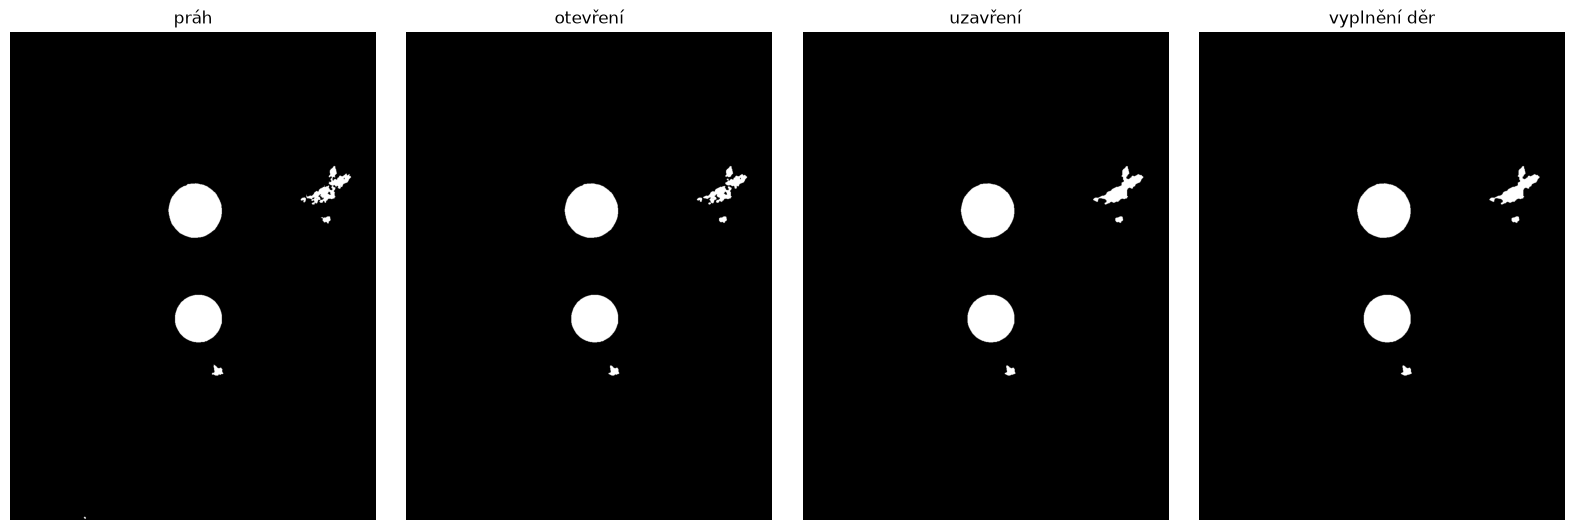

In [5]:
raw = threshold_hysteresis(v["2.jpg"])
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
opened = cv2.morphologyEx(raw, cv2.MORPH_OPEN, kernel)
closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel, iterations=2)
filled = clean_mask(raw)

show_images([raw, opened, closed, filled], ["práh", "otevření", "uzavření", "vyplnění děr"], cols=4, size=4)

## Nalezené mince

1.jpg: 11 mincí
2.jpg: 2 mincí


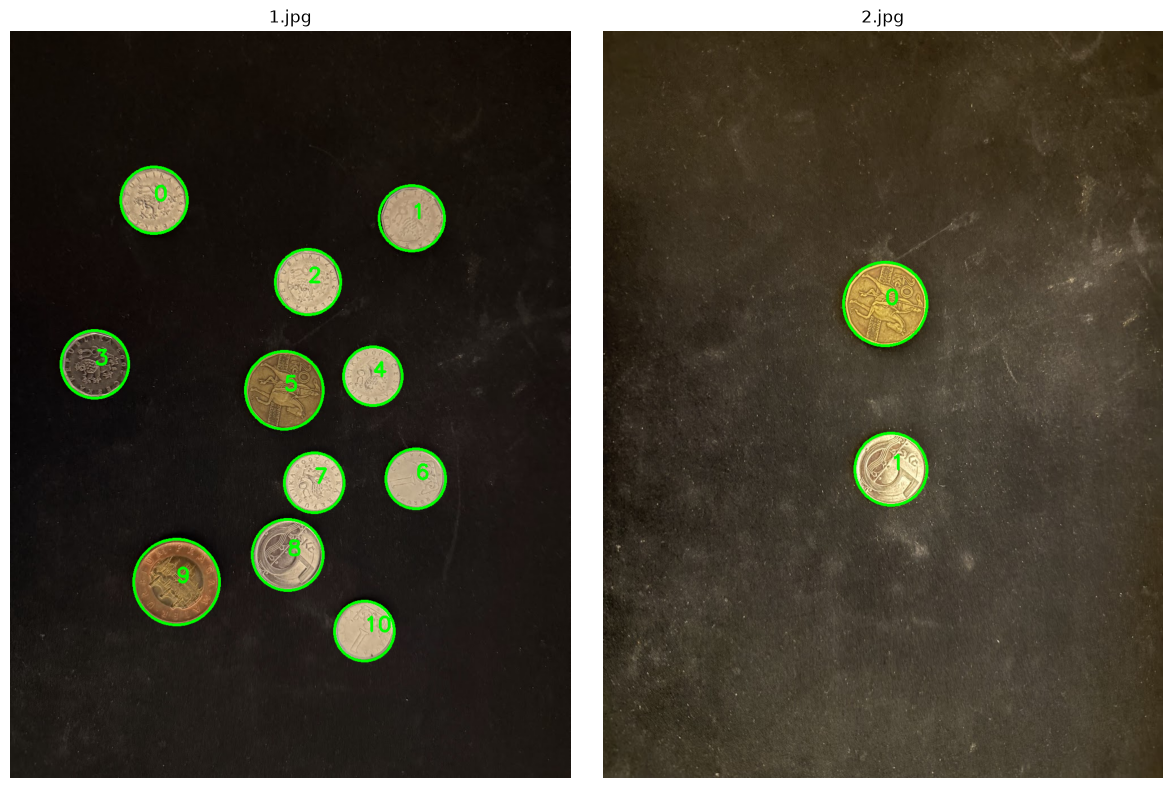

In [6]:
results = {}
for name, img in images.items():
    mask = segment(v[name])
    results[name] = find_coins(mask)
    print(f"{name}: {len(results[name])} mincí")

show_images([draw_coins(images[n], results[n]) for n in images], list(images), cols=2, size=6)

In [7]:
df = pd.DataFrame([
    {"snímek": name, "id": i, "x": round(c["x"]), "y": round(c["y"]), "r_px": round(c["r"], 1),
     "plocha_px": round(c["area"]), "kruhovitost": round(c["circularity"], 2)}
    for name, coins in results.items() for i, c in enumerate(coins)
])
df.sort_values(["snímek", "r_px"])

,snímek,id,x,y,r_px,plocha_px,kruhovitost
4,1.jpg,4,643,612,52.8,8510,0.90
7,1.jpg,7,540,801,53.1,8641,0.90
6,1.jpg,6,719,794,53.5,8685,0.90
10,1.jpg,10,628,1064,53.7,8612,0.90
1,1.jpg,1,713,333,58.3,10120,0.90
2,1.jpg,2,528,446,58.3,10204,0.90
0,1.jpg,0,255,301,59.2,10539,0.90
3,1.jpg,3,151,591,60.3,10816,0.89
8,1.jpg,8,493,929,63.2,11963,0.90
5,1.jpg,5,487,638,69.2,14718,0.89


In [8]:
out = ROOT / "results"
df.to_csv(out / "03_mince.csv", index=False)
for name, img in images.items():
    vis = draw_coins(img, results[name])
    cv2.imwrite(str(out / f"03_{Path(name).stem}.jpg"), cv2.cvtColor(vis, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 80])